# 05 Shoreline positional uncertainty (DSAS_uncy)

**Manuscript outputs:** Figure 3, Table A2; DSAS-ready shorelines for DSAS v6.2.86

**Inputs:** transects and baseline, annual shorelines (EPSG:32737), clipped SRTM, U_eta (stage 03), RMSE_y (stage 02)

**Next step is manual:** run DSAS v6.2.86 in ArcGIS Pro on `ke_shorelines_2000_2024_DSAS_READY` (uncertainty field `DSAS_uncy`, 30 m transects, 90% confidence interval) and save the rates layer as `Data/Output/DSAS_Uncertainty_Final/DSAS_rates/ke_30mtr_transects_dsas_uncy.gpkg`.

Inputs are read from `Master_raw/`; everything produced is written to `Outputs/` (manuscript figures in `Outputs/Figures`, tables in `Outputs/Tables`). The first code cell lists every path. Run the cells in order.

# DSAS shoreline uncertainty — clean end-to-end production workflow

This is the consolidated production notebook after the development/QC work.

**Raw inputs**
- DSAS 30 m transects (`ke_30mtr_transects`) and baseline (`ke_baseline`)
- dated shoreline layer
- SRTM 30 m DEM
- annual EOT20/UTide vertical tidal uncertainty (`U_eta_m`)
- annual Landsat geometric RMSE

**Validated method**
1. Intersect transects with shorelines.
2. Collapse coincident crossings and retain the END-most crossing per transect-year.
3. Confirm that the DSAS baseline is at/near the transect START.
4. Temporarily extend transect END by 120 m for DEM sampling only.
5. Sample SRTM every 15 m and fit the local profile over ±90 m.
6. Calculate horizontal tidal displacement: `U_tide = |U_eta| / tan(beta)`.
7. Save RAW profile adequacy diagnostics.
8. Apply profile QC: `n>=3`, `>=3` unique elevations, elevation range `>0`, `R²>=0.50`, finite positive slope and finite `U_tide`.
9. Use the median QC-passed `U_tide` per shoreline feature.
10. Combine with annual Landsat RMSE: `DSAS_uncy = sqrt(RMSE² + U_tide²)`.
11. Where a shoreline feature has no local QC estimate, use the same-year median QC-derived `U_tide`, explicitly flagged as a fallback.
12. Export the DSAS-ready shoreline and annual error matrix.

The old constant 15 m shoreline uncertainty is retained only as provenance (`DSAS_uncy_old`) and is not used in the final calculation.


In [ ]:
from pathlib import Path

# ------------------------------------------------------------
# REPOSITORY ROOT: first folder above this notebook that contains Master_raw
# (e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024)
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No Master_raw folder found above {_here}. Open this notebook inside the repository.")
RAW = ROOT / "Master_raw"          # inputs
OUTPUTS = ROOT / "Outputs"         # everything this repository produces
FIGURES = OUTPUTS / "Figures"      # manuscript figures
TABLES = OUTPUTS / "Tables"        # manuscript tables
TEXT_STATS = TABLES / "Text_statistics"
for _d in (FIGURES, TABLES, TEXT_STATS):
    _d.mkdir(parents=True, exist_ok=True)
OVERWRITE = True                   # re-running replaces this notebook's earlier outputs


def first_existing(*candidates):
    """Return the first path that exists (otherwise the first one)."""
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return Path(candidates[0])


def save_table(df, name, index=False, folder=None):
    path = (folder or TABLES) / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Saved:", path)


def save_figure(fig, name, dpi=600):
    for ext in ("jpg",):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
    print("Saved:", FIGURES / f"{name}.jpg")


def remove_existing(*files):
    for f in map(Path, files):
        for t in (list(f.parent.glob(f.stem + ".*")) if f.suffix == ".shp" else [f]):
            if t.exists():
                if not OVERWRITE:
                    raise FileExistsError(t)
                t.unlink()

# ------------------------------------------------------------
# INPUTS AND OUTPUT FOLDERS FOR THIS NOTEBOOK
# ------------------------------------------------------------
EOT20_OUT_DIR = OUTPUTS / "EOT20_PMSL_tide"
U_ETA_CSV = EOT20_OUT_DIR / "Utide_Vertical_Tide_Input_Mombasa.csv"
ELEVATION_DIR = OUTPUTS / "Elevation_slope"
DEM_UTM_TIF = first_existing(ELEVATION_DIR / "Kenya_Coast_SRTM30m_UTM37S.tif", RAW / "Elevation" / "Kenya_Coast_SRTM30m_UTM37S.tif")
DSAS_INPUT_DIR = RAW / "DSAS_inputs"
SHORELINES_UTM_SHP = RAW /"Raw_Transects_no rates" / "ke_shorelines_2000_2024_UTM37S.shp"
TRANSECTS_GPKG = RAW / "Raw_Transects_no rates" / "ke_transects_30mtr.gpkg"
TRANSECT_LAYER = "ke_30mtr_transects"
BASELINE_LAYER = "ke_baseline"
LANDSAT_SUMMARY_DIR = OUTPUTS / "Landsat_sensor_summary"
RMSE_Y_CSV = LANDSAT_SUMMARY_DIR / "year_geometric_rmse_majority_sensor.csv"
DSAS_UNCY_DIR = OUTPUTS / "DSAS_Uncertainty"
PROFILE_RAW_CSV = DSAS_UNCY_DIR / "01_Profile_Adequacy_Diagnostic_90m_RAW.csv"
PROFILE_QC_CSV = DSAS_UNCY_DIR / "02_Profile_Adequacy_Diagnostic_90m_QC.csv"
DSAS_READY_GPKG = DSAS_UNCY_DIR / "ke_shorelines_2000_2024_DSAS_READY.gpkg"
DSAS_READY_SHP = DSAS_UNCY_DIR / "ke_shorelines_2000_2024_DSAS_READY.shp"
ERROR_MATRIX_CSV = DSAS_UNCY_DIR / "04_Annual_DSAS_Uncertainty_Error_Matrix.csv"

print("Repository root:", ROOT)
for _label, _p in [("TRANSECTS_GPKG", TRANSECTS_GPKG), ("SHORELINES_UTM_SHP", SHORELINES_UTM_SHP), ("DEM_UTM_TIF", DEM_UTM_TIF), ("U_ETA_CSV", U_ETA_CSV), ("RMSE_Y_CSV", RMSE_Y_CSV)]:
    print(f"  {'ok     ' if _p.exists() else 'MISSING'} {_label}: {_p.relative_to(ROOT) if _p.is_relative_to(ROOT) else _p}")

# ============================================================
# 01 — Imports, paths and fixed production settings
# ============================================================

from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from shapely.geometry import LineString


TRANSECTS_PATH = TRANSECTS_GPKG
SHORELINES_PATH = SHORELINES_UTM_SHP
DEM_PATH = DEM_UTM_TIF
EOT20_CSV = U_ETA_CSV
RMSE_CSV = RMSE_Y_CSV
OUTPUT_DIR = DSAS_UNCY_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Final validated settings
HALF_WINDOW_M = 90.0
PROFILE_EXTENSION_M = 120.0
PROFILE_SAMPLE_SPACING_M = 15.0
MIN_PROFILE_SAMPLES = 3
R2_MIN = 0.50
COINCIDENT_TOL_M = 0.01

RAW_CSV = PROFILE_RAW_CSV
QC_CSV = PROFILE_QC_CSV
FINAL_GPKG = DSAS_READY_GPKG
FINAL_SHP = DSAS_READY_SHP

print("Production output folder:", OUTPUT_DIR)


Repository root: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
  ok      TRANSECTS_GPKG: Master_raw\Raw_Transects_no rates\ke_transects_30mtr.gpkg
  ok      SHORELINES_UTM_SHP: Master_raw\Raw_Transects_no rates\ke_shorelines_2000_2024_UTM37S.shp
  ok      DEM_UTM_TIF: Outputs\Elevation_slope\Kenya_Coast_SRTM30m_UTM37S.tif
  ok      U_ETA_CSV: Outputs\EOT20_PMSL_tide\Utide_Vertical_Tide_Input_Mombasa.csv
  ok      RMSE_Y_CSV: Outputs\Landsat_sensor_summary\year_geometric_rmse_majority_sensor.csv
Production output folder: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty


In [ ]:
# ============================================================
# 02 — Read spatial and annual uncertainty inputs
# ============================================================

transects = gpd.read_file(TRANSECTS_PATH, layer=TRANSECT_LAYER)
baseline = gpd.read_file(TRANSECTS_PATH, layer=BASELINE_LAYER)
shorelines = gpd.read_file(SHORELINES_PATH).reset_index(drop=True)

with rasterio.open(DEM_PATH) as src:
    dem_crs = src.crs
    print("DEM CRS:", dem_crs)
    print("DEM resolution:", src.res)

for name, gdf in [("transects", transects), ("baseline", baseline), ("shorelines", shorelines)]:
    if gdf.crs is None:
        raise ValueError(f"{name} has no defined CRS.")

if transects.crs != dem_crs:
    transects = transects.to_crs(dem_crs)
if baseline.crs != dem_crs:
    baseline = baseline.to_crs(dem_crs)
if shorelines.crs != dem_crs:
    shorelines = shorelines.to_crs(dem_crs)

# Stable working transect ID
def choose_existing_field(columns, candidates):
    lower = {c.lower(): c for c in columns}
    for c in candidates:
        if c.lower() in lower:
            return lower[c.lower()]
    return None

tid_src = choose_existing_field(
    transects.columns, ["Trans_ID", "Transect_ID", "TRANSORDER", "TransectID", "TCD"]
)
if tid_src is not None:
    transects["Transect_ID"] = transects[tid_src]
else:
    transects["Transect_ID"] = np.arange(1, len(transects) + 1)

if transects["Transect_ID"].isna().any() or not transects["Transect_ID"].is_unique:
    transects["Transect_ID"] = np.arange(1, len(transects) + 1)

# Shoreline year
year_src = choose_existing_field(
    shorelines.columns, ["shre_yr", "year", "Year", "YEAR", "ShoreYear", "shore_year"]
)
if year_src is None:
    raise ValueError(f"No shoreline year field found. Fields: {list(shorelines.columns)}")

shorelines["Shore_Year"] = pd.to_numeric(shorelines[year_src], errors="coerce")
if shorelines["Shore_Year"].isna().any():
    raise ValueError("One or more shoreline features have no valid year.")
shorelines["Shore_Year"] = shorelines["Shore_Year"].astype(int)

# IMPORTANT: this exactly reproduces the verified original working ID.
shorelines["Shoreline_ID"] = [f"SL_{i}" for i in range(1, len(shorelines) + 1)]

tide = pd.read_csv(EOT20_CSV)
rmse = pd.read_csv(RMSE_CSV)

if not {"year", "U_eta_m"}.issubset(tide.columns):
    raise ValueError("EOT20 table must contain year and U_eta_m.")
if not {"year", "geometric_rmse_model"}.issubset(rmse.columns):
    raise ValueError("RMSE table must contain year and geometric_rmse_model.")

tide["year"] = pd.to_numeric(tide["year"], errors="coerce")
tide["U_eta_m"] = pd.to_numeric(tide["U_eta_m"], errors="coerce")
rmse["year"] = pd.to_numeric(rmse["year"], errors="coerce")
rmse["geometric_rmse_model"] = pd.to_numeric(rmse["geometric_rmse_model"], errors="coerce")

if tide["year"].duplicated().any():
    raise ValueError("Duplicate years in EOT20 table.")
if rmse["year"].duplicated().any():
    raise ValueError("Duplicate years in RMSE table.")

print("Transects :", f"{len(transects):,}")
print("Shorelines:", f"{len(shorelines):,}")
print("Years     :", f"{shorelines.Shore_Year.min()}–{shorelines.Shore_Year.max()}")


DEM CRS: EPSG:32737
DEM resolution: (30.0, 30.0)
Transects : 12,468
Shorelines: 1,263
Years     : 2000–2024


In [ ]:
# ============================================================
# 03 — Build shoreline × transect intersections
# ============================================================

t_small = transects[["Transect_ID", "geometry"]].copy()
s_small = shorelines[["Shoreline_ID", "Shore_Year", "geometry"]].copy()

intersections = gpd.overlay(
    t_small, s_small, how="intersection", keep_geom_type=False
).explode(index_parts=False, ignore_index=True)

# Only point crossings are usable as shoreline positions.
intersections = intersections.loc[
    intersections.geometry.geom_type.eq("Point")
].copy().reset_index(drop=True)

intersections["Int_ID"] = np.arange(1, len(intersections) + 1)

geom_map = transects.set_index("Transect_ID").geometry.to_dict()
line_geoms = gpd.GeoSeries(
    intersections["Transect_ID"].map(geom_map), crs=dem_crs
)
intersections["dist_along_m"] = shapely.line_locate_point(
    line_geoms.array, intersections.geometry.array
)

print("Raw point intersections:", f"{len(intersections):,}")


Raw point intersections: 422,560


In [ ]:
# ============================================================
# 04 — Collapse coincident crossings and retain END-most crossing
# ============================================================

# The shoreline dataset has one shoreline date per year in this analysis.
intersections["_shore_time"] = pd.to_datetime(
    intersections["Shore_Year"].astype(str) + "-01-01"
)

# Collapse the same geometric crossing represented by adjacent fragments.
intersections["_dist_cluster"] = np.round(
    intersections["dist_along_m"] / COINCIDENT_TOL_M
).astype("Int64")

intersections_clean = (
    intersections
    .sort_values(["Transect_ID", "_shore_time", "dist_along_m", "Shoreline_ID"])
    .drop_duplicates(
        subset=["Transect_ID", "_shore_time", "_dist_cluster"],
        keep="first"
    )
    .copy()
)

# Verify orientation independently from the DSAS baseline.
tb = gpd.overlay(
    transects[["Transect_ID", "geometry"]],
    baseline[["geometry"]],
    how="intersection",
    keep_geom_type=False
).explode(index_parts=False, ignore_index=True)

tb = tb.loc[tb.geometry.geom_type.eq("Point")].copy()
tb["baseline_dist_m"] = tb.apply(
    lambda r: float(geom_map[r["Transect_ID"]].project(r.geometry)),
    axis=1
)

baseline_counts = tb.groupby("Transect_ID").size()
unique_baseline_ids = baseline_counts[baseline_counts == 1].index
tb_unique = tb.loc[
    tb["Transect_ID"].isin(unique_baseline_ids),
    ["Transect_ID", "baseline_dist_m"]
].copy()

lengths = transects.set_index("Transect_ID").geometry.length.rename("transect_length_m")
orient = tb_unique.merge(lengths, left_on="Transect_ID", right_index=True)
orient["baseline_fraction"] = orient["baseline_dist_m"] / orient["transect_length_m"]

print("Transects with one baseline crossing:", f"{len(orient):,}")
print("Median baseline fraction:", float(orient["baseline_fraction"].median()))

if len(orient) == 0 or (orient["baseline_fraction"] < 0.5).mean() < 0.95:
    raise RuntimeError(
        "Transect orientation is not sufficiently verified as START=baseline. "
        "Do not apply the END-most shoreline rule."
    )

# Retain one shoreline position per transect-year.
work = intersections_clean.merge(
    lengths, left_on="Transect_ID", right_index=True, how="left"
)
work["distance_from_end_m"] = work["transect_length_m"] - work["dist_along_m"]
work["n_crossings_original"] = (
    work.groupby(["Transect_ID", "Shore_Year"])["Int_ID"].transform("size")
)
work["rank_from_end"] = (
    work.groupby(["Transect_ID", "Shore_Year"])["dist_along_m"]
    .rank(method="first", ascending=False)
)

intersections = (
    work.loc[work["rank_from_end"] == 1]
    .copy()
    .reset_index(drop=True)
)

check = intersections.groupby(["Transect_ID", "Shore_Year"]).size()
if check.max() != 1:
    raise RuntimeError("Multiple crossings remain after END-most resolution.")

print("Resolved intersections:", f"{len(intersections):,}")
print("Removed extras:", f"{len(intersections_clean)-len(intersections):,}")
print("Median selected distance from transect END:",
      round(float(intersections["distance_from_end_m"].median()), 2), "m")


Transects with one baseline crossing: 6,232
Median baseline fraction: 4.105685434528573e-14
Resolved intersections: 301,661
Removed extras: 120,899
Median selected distance from transect END: 19.55 m


In [ ]:
# ============================================================
# 05 — Temporarily extend transect END and sample SRTM DEM
# ============================================================

def extend_line_end(line, extension_m):
    if line is None or line.is_empty or line.geom_type != "LineString":
        return None
    coords = list(line.coords)
    if len(coords) < 2:
        return None
    x1, y1 = coords[-2]
    x2, y2 = coords[-1]
    dx, dy = x2-x1, y2-y1
    seg_len = np.hypot(dx, dy)
    if seg_len == 0:
        return None
    new_end = (x2 + dx/seg_len*extension_m, y2 + dy/seg_len*extension_m)
    return LineString(coords + [new_end])

extended = {
    tid: extend_line_end(geom, PROFILE_EXTENSION_M)
    for tid, geom in geom_map.items()
}

ranges = intersections.groupby("Transect_ID")["dist_along_m"].agg(["min", "max"])
profile_cache = {}

with rasterio.open(DEM_PATH) as src:
    nodata = src.nodata
    total = len(ranges)

    for counter, (tid, row) in enumerate(ranges.iterrows(), start=1):
        line = extended.get(tid)
        if line is None or line.is_empty:
            continue

        start_m = max(0.0, float(row["min"]) - HALF_WINDOW_M)
        end_m = min(line.length, float(row["max"]) + HALF_WINDOW_M)
        if end_m <= start_m:
            continue

        d = np.arange(
            start_m, end_m + PROFILE_SAMPLE_SPACING_M, PROFILE_SAMPLE_SPACING_M
        )
        d = d[d <= line.length]
        if len(d) < MIN_PROFILE_SAMPLES:
            continue

        pts = [line.interpolate(float(x)) for x in d]
        vals = list(src.sample([(p.x, p.y) for p in pts], masked=True))
        z = np.array([
            np.nan if np.ma.is_masked(v[0]) else float(v[0]) for v in vals
        ], dtype=float)

        if nodata is not None:
            z[np.isclose(z, nodata, equal_nan=False)] = np.nan
        z[~np.isfinite(z)] = np.nan

        profile_cache[tid] = {"distance_m": d, "elevation_m": z}

        if counter % 1000 == 0 or counter == total:
            print(f"Sampled {counter:,}/{total:,} transects")

print("Cached profiles:", f"{len(profile_cache):,}")


Sampled 1,000/12,466 transects
Sampled 2,000/12,466 transects
Sampled 3,000/12,466 transects
Sampled 4,000/12,466 transects
Sampled 5,000/12,466 transects
Sampled 6,000/12,466 transects
Sampled 7,000/12,466 transects
Sampled 8,000/12,466 transects
Sampled 9,000/12,466 transects
Sampled 10,000/12,466 transects
Sampled 11,000/12,466 transects
Sampled 12,000/12,466 transects
Sampled 12,466/12,466 transects
Cached profiles: 12,466


In [ ]:
# ============================================================
# 06 — Fit ±90 m local profile slope and R²
# ============================================================

def prepare_profile(d, z):
    d = np.asarray(d, dtype=float)
    z = np.asarray(z, dtype=float)
    valid = np.isfinite(d) & np.isfinite(z)
    n = valid.astype(np.int64)
    x = np.where(valid, d, 0.0)
    y = np.where(valid, z, 0.0)

    def cs(a):
        return np.concatenate([[0.0], np.cumsum(a)])

    return {
        "d": d, "z": z,
        "n": np.concatenate([[0], np.cumsum(n)]),
        "sx": cs(x), "sy": cs(y),
        "sxx": cs(x*x), "syy": cs(y*y), "sxy": cs(x*y)
    }

def isum(c, i0, i1):
    return c[i1] - c[i0]

def fit_local(prep, center, half_window):
    d = prep["d"]
    i0 = int(np.searchsorted(d, center-half_window, side="left"))
    i1 = int(np.searchsorted(d, center+half_window, side="right"))
    n = int(isum(prep["n"], i0, i1))
    if n < MIN_PROFILE_SAMPLES:
        return np.nan, np.nan, n

    sx, sy = isum(prep["sx"],i0,i1), isum(prep["sy"],i0,i1)
    sxx, syy = isum(prep["sxx"],i0,i1), isum(prep["syy"],i0,i1)
    sxy = isum(prep["sxy"],i0,i1)

    denx = n*sxx - sx*sx
    if denx <= 0:
        return np.nan, np.nan, n

    b = (n*sxy - sx*sy) / denx
    deny = n*syy - sy*sy
    r2 = np.nan
    if deny > 0:
        r = (n*sxy - sx*sy) / math.sqrt(denx*deny)
        r2 = float(np.clip(r*r, 0.0, 1.0))

    return math.degrees(math.atan(abs(b))), r2, n

prepared = {
    tid: prepare_profile(p["distance_m"], p["elevation_m"])
    for tid, p in profile_cache.items()
}

slopes = np.full(len(intersections), np.nan)
r2s = np.full(len(intersections), np.nan)
ns = np.zeros(len(intersections), dtype=int)

for i, row in enumerate(
    intersections[["Transect_ID","dist_along_m"]].itertuples(index=False)
):
    prep = prepared.get(row.Transect_ID)
    if prep is None:
        continue
    slopes[i], r2s[i], ns[i] = fit_local(
        prep, float(row.dist_along_m), HALF_WINDOW_M
    )

intersections["slope_deg"] = slopes
intersections["r2"] = r2s
intersections["n_fit_samples"] = ns

print("Finite slope fits:", f"{np.isfinite(slopes).sum():,}/{len(slopes):,}")


Finite slope fits: 230,455/301,661


In [ ]:
# ============================================================
# 07 — Join annual EOT20 term and calculate point-level U_tide
# ============================================================

intersections = intersections.merge(
    tide[["year","U_eta_m"]].rename(columns={"year":"Shore_Year"}),
    on="Shore_Year", how="left", validate="many_to_one"
)

if intersections["U_eta_m"].isna().any():
    yrs = sorted(intersections.loc[intersections["U_eta_m"].isna(),"Shore_Year"].unique())
    raise ValueError(f"Missing U_eta_m for shoreline years: {yrs}")

beta = pd.to_numeric(intersections["slope_deg"], errors="coerce")
tan_beta = np.tan(np.deg2rad(beta))

valid = (
    np.isfinite(beta) & (beta > 0) & (beta < 90)
    & np.isfinite(tan_beta) & (tan_beta > 0)
)

intersections["U_tide_m"] = np.nan
intersections.loc[valid, "U_tide_m"] = (
    np.abs(intersections.loc[valid, "U_eta_m"].to_numpy(float))
    / tan_beta[valid]
)

print("Finite U_tide values:",
      f"{np.isfinite(intersections['U_tide_m']).sum():,}/{len(intersections):,}")


Finite U_tide values: 228,901/301,661


In [ ]:
# ============================================================
# 08 — Build and save RAW ±90 m profile adequacy table
# ============================================================

records = []

for row in intersections[
    ["Int_ID","Transect_ID","Shoreline_ID","Shore_Year",
     "dist_along_m","slope_deg","r2","U_tide_m"]
].itertuples(index=False):

    prep = prepared.get(row.Transect_ID)
    if prep is None:
        continue

    d = np.asarray(prep["d"], dtype=float)
    z = np.asarray(prep["z"], dtype=float)
    mask = (
        np.isfinite(d) & np.isfinite(z)
        & (d >= row.dist_along_m - HALF_WINDOW_M)
        & (d <= row.dist_along_m + HALF_WINDOW_M)
    )

    x = d[mask] - row.dist_along_m
    elev = z[mask]
    if len(x) == 0:
        continue

    min_x, max_x = np.min(x), np.max(x)
    elev_min, elev_max = np.min(elev), np.max(elev)

    records.append({
        "Int_ID": row.Int_ID,
        "Transect_ID": row.Transect_ID,
        "Shoreline_ID": row.Shoreline_ID,
        "Shore_Year": row.Shore_Year,
        "n_total": len(x),
        "n_seaward": int(np.sum(x < 0)),
        "n_landward": int(np.sum(x > 0)),
        "n_at_shore": int(np.sum(np.isclose(x, 0))),
        "seaward_extent_m": abs(min(min_x, 0)),
        "landward_extent_m": max(max_x, 0),
        "total_sampled_extent_m": abs(min(min_x,0)) + max(max_x,0),
        "elev_min_m": elev_min,
        "elev_max_m": elev_max,
        "elev_range_m": elev_max-elev_min,
        "n_unique_elev": len(np.unique(elev)),
        "bilateral_profile": bool(np.any(x < 0) and np.any(x > 0)),
        "slope_deg": row.slope_deg,
        "r2": row.r2,
        "U_tide_m": row.U_tide_m
    })

profile_raw = pd.DataFrame(records)
profile_raw.to_csv(RAW_CSV, index=False)

print("RAW profiles:", f"{len(profile_raw):,}")
print("Saved:", RAW_CSV)


RAW profiles: 253,849
Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\01_Profile_Adequacy_Diagnostic_90m_RAW.csv


In [ ]:
# ============================================================
# 09 — Apply final profile QC and save QC table
# ============================================================

qc_pass = (
    profile_raw["n_total"].ge(MIN_PROFILE_SAMPLES)
    & profile_raw["n_unique_elev"].ge(3)
    & profile_raw["elev_range_m"].gt(0)
    & profile_raw["r2"].ge(R2_MIN)
    & np.isfinite(profile_raw["slope_deg"])
    & profile_raw["slope_deg"].gt(0)
    & np.isfinite(profile_raw["U_tide_m"])
)

profile_qc = profile_raw.copy()
profile_qc["QC_pass"] = qc_pass

def qc_reason(r):
    reasons = []
    if r["n_total"] < MIN_PROFILE_SAMPLES: reasons.append("fewer_than_3_samples")
    if r["n_unique_elev"] < 3: reasons.append("fewer_than_3_unique_elevations")
    if not np.isfinite(r["elev_range_m"]) or r["elev_range_m"] <= 0:
        reasons.append("zero_or_invalid_elevation_range")
    if not np.isfinite(r["r2"]) or r["r2"] < R2_MIN:
        reasons.append("R2_below_0.50_or_invalid")
    if not np.isfinite(r["slope_deg"]) or r["slope_deg"] <= 0:
        reasons.append("zero_or_invalid_slope")
    if not np.isfinite(r["U_tide_m"]):
        reasons.append("invalid_Utide")
    return "PASS" if not reasons else ";".join(reasons)

profile_qc["QC_reason"] = profile_qc.apply(qc_reason, axis=1)
profile_qc.to_csv(QC_CSV, index=False)

print("Total profiles:", f"{len(profile_qc):,}")
print("QC passed:", f"{profile_qc['QC_pass'].sum():,}",
      f"({100*profile_qc['QC_pass'].mean():.2f}%)")
print("Saved:", QC_CSV)


Total profiles: 253,849
QC passed: 169,598 (66.81%)
Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\02_Profile_Adequacy_Diagnostic_90m_QC.csv


In [ ]:
# ============================================================
# 10 — Shoreline-level U_tide + annual RMSE
# ============================================================

qc_ok = profile_qc.loc[profile_qc["QC_pass"]].copy()

shore_unc = (
    qc_ok.groupby(["Shoreline_ID","Shore_Year"])
    .agg(
        n_valid_profiles=("U_tide_m","size"),
        U_tide_final_m=("U_tide_m","median")
    )
    .reset_index()
)

rmse_year = (
    rmse[["year","geometric_rmse_model"]]
    .rename(columns={"year":"Shore_Year","geometric_rmse_model":"RMSE_m"})
)

shore_unc = shore_unc.merge(
    rmse_year, on="Shore_Year", how="left", validate="many_to_one"
)

if shore_unc["RMSE_m"].isna().any():
    raise ValueError("Missing annual RMSE for one or more shoreline uncertainty records.")

shore_unc["DSAS_uncy_QC"] = np.sqrt(
    shore_unc["RMSE_m"]**2 + shore_unc["U_tide_final_m"]**2
)

print("QC-derived shoreline features:", f"{len(shore_unc):,}")


QC-derived shoreline features: 805


In [ ]:
# ============================================================
# 11 — Join to all shorelines and apply same-year median fallback
# ============================================================

# Preserve the original constant field for provenance.
if "DSAS_uncy" in shorelines.columns:
    shorelines = shorelines.rename(columns={"DSAS_uncy":"DSAS_uncy_old"})

joined = shorelines.merge(
    shore_unc[
        ["Shoreline_ID","Shore_Year","n_valid_profiles",
         "U_tide_final_m","RMSE_m","DSAS_uncy_QC"]
    ],
    on=["Shoreline_ID","Shore_Year"],
    how="left",
    validate="one_to_one"
)

annual_fallback = (
    shore_unc.groupby("Shore_Year")
    .agg(
        annual_Utide_median_m=("U_tide_final_m","median"),
        annual_n_QC_shorelines=("U_tide_final_m","size")
    )
    .reset_index()
)

joined = joined.merge(
    annual_fallback, on="Shore_Year", how="left", validate="many_to_one"
)

joined["Uncy_method"] = np.where(
    joined["U_tide_final_m"].notna(),
    "QC_DERIVED",
    "YEAR_MEDIAN_FALLBACK"
)

joined["U_tide_used_m"] = joined["U_tide_final_m"].fillna(
    joined["annual_Utide_median_m"]
)

rmse_map = dict(zip(rmse_year["Shore_Year"], rmse_year["RMSE_m"]))
joined["RMSE_m"] = joined["RMSE_m"].fillna(
    joined["Shore_Year"].map(rmse_map)
)

joined["DSAS_uncy"] = np.sqrt(
    joined["RMSE_m"]**2 + joined["U_tide_used_m"]**2
)

if len(joined) != len(shorelines):
    raise RuntimeError("Feature count changed during uncertainty join.")
if joined["DSAS_uncy"].isna().any():
    raise RuntimeError("Final DSAS_uncy contains missing values.")

print("Total shorelines:", f"{len(joined):,}")
print("QC-derived:", f"{(joined.Uncy_method=='QC_DERIVED').sum():,}")
print("Year fallback:", f"{(joined.Uncy_method=='YEAR_MEDIAN_FALLBACK').sum():,}")
print("Missing DSAS_uncy:", int(joined["DSAS_uncy"].isna().sum()))


Total shorelines: 1,263
QC-derived: 805
Year fallback: 458
Missing DSAS_uncy: 0


In [ ]:
# ============================================================
# 12 — Export DSAS-ready shoreline and annual error matrix
# ============================================================

# Keep useful provenance/QC fields in the GeoPackage.
final_shorelines = joined.copy()
remove_existing(FINAL_GPKG, FINAL_SHP)

final_shorelines.to_file(
    FINAL_GPKG,
    layer="shorelines_DSAS_ready",
    driver="GPKG"
)

# Shapefile is included only for DSAS/software compatibility.
# Field names may be shortened by the shapefile format.
final_shorelines.to_file(FINAL_SHP, driver="ESRI Shapefile")

# Annual reporting/error matrix: use only QC-derived shoreline values
# so fallback repetitions do not affect the annual U_tide statistic.
annual_error_matrix = (
    shore_unc.groupby("Shore_Year")
    .agg(
        n_QC_shorelines=("U_tide_final_m","size"),
        U_tide_m=("U_tide_final_m","median"),
        RMSE_m=("RMSE_m","first")
    )
    .reset_index()
    .rename(columns={"Shore_Year":"Year"})
)

annual_error_matrix["DSAS_uncy_m"] = np.sqrt(
    annual_error_matrix["RMSE_m"]**2
    + annual_error_matrix["U_tide_m"]**2
)

for c in ["U_tide_m","RMSE_m","DSAS_uncy_m"]:
    annual_error_matrix[c] = annual_error_matrix[c].round(3)

annual_error_matrix.to_csv(ERROR_MATRIX_CSV, index=False)

print("\nFINAL OUTPUTS")
print("1.", RAW_CSV)
print("2.", QC_CSV)
print("3.", FINAL_GPKG)
print("   ", FINAL_SHP)
print("4.", ERROR_MATRIX_CSV)

display(annual_error_matrix)



FINAL OUTPUTS
1. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\01_Profile_Adequacy_Diagnostic_90m_RAW.csv
2. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\02_Profile_Adequacy_Diagnostic_90m_QC.csv
3. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\ke_shorelines_2000_2024_DSAS_READY.gpkg
    D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\ke_shorelines_2000_2024_DSAS_READY.shp
4. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\DSAS_Uncertainty\04_Annual_DSAS_Uncertainty_Error_Matrix.csv


C:\Users\jmbug\AppData\Local\Temp\ipykernel_27168\2226411097.py:17: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_shorelines.to_file(FINAL_SHP, driver="ESRI Shapefile")
C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'DSAS_uncy_old' to 'DSAS_uncy_'
  ogr_write(
C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'Shoreline_ID' to 'Shoreline_'
  ogr_write(
C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'n_valid_profiles' to 'n_valid_pr'
  ogr_write(
C:\Users

,Year,n_QC_shorelines,U_tide_m,RMSE_m,DSAS_uncy_m
0,2000,16,40.113,5.069,40.432
1,2001,24,56.005,4.947,56.223
2,2002,29,46.489,4.838,46.740
3,2003,38,52.447,4.995,52.684
4,2004,31,39.709,5.225,40.051
5,2005,31,51.399,5.028,51.644
6,2006,37,44.761,4.950,45.034
7,2007,33,46.196,5.442,46.515
8,2008,29,52.237,5.068,52.482
9,2009,35,53.629,4.931,53.856


## Files to retain after a successful clean run

The production folder is intentionally limited to the essential outputs:

1. `01_Profile_Adequacy_Diagnostic_90m_RAW.csv` — complete profile adequacy evidence before QC.
2. `02_Profile_Adequacy_Diagnostic_90m_QC.csv` — same profiles with `QC_pass` and `QC_reason`.
3. `03_ke_shorelines_2000_2024_DSAS_READY.gpkg` — final shoreline layer with `DSAS_uncy`, method/provenance fields and geometry.
4. `03_ke_shorelines_2000_2024_DSAS_READY.shp` — compatibility copy.
5. `04_Annual_DSAS_Uncertainty_Error_Matrix.csv` — annual `U_tide`, Landsat RMSE and combined reference uncertainty.

Do not delete the raw source datasets. The earlier development notebooks can be archived separately once this clean notebook reproduces the expected QA counts and distributions.


Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Figures\Figure_3_Shoreline_positional_uncertainty_2000_2024.png


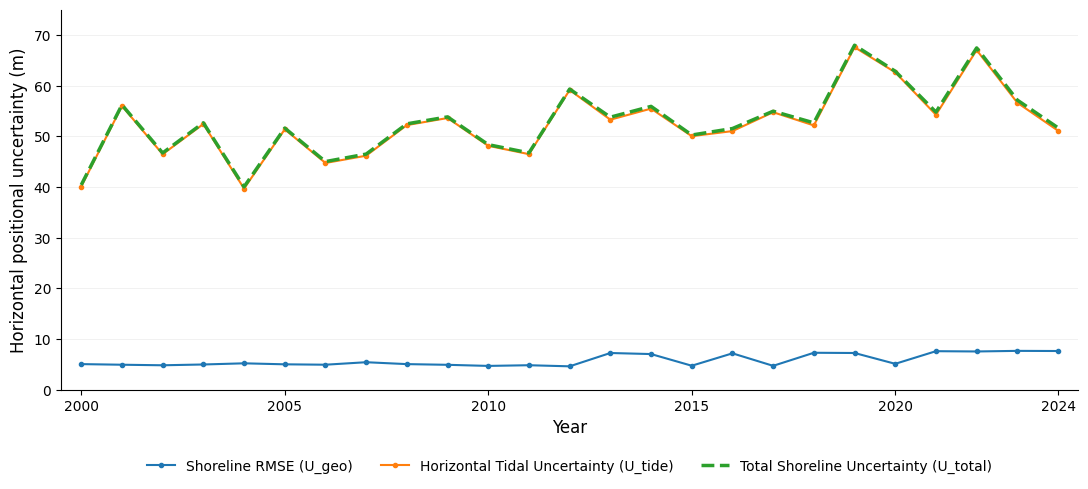

In [ ]:
# ============================================================
# PLOT FINAL DSAS UNCERTAINTY
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(ERROR_MATRIX_CSV)

# Ensure correct order
df = df.sort_values("Year")


fig, ax = plt.subplots(figsize=(11, 5))


# ------------------------------------------------------------
# Individual uncertainty components
# ------------------------------------------------------------

ax.plot(
    df["Year"],
    df["RMSE_m"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Shoreline RMSE (U_geo)"
)

ax.plot(
    df["Year"],
    df["U_tide_m"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Horizontal Tidal Uncertainty (U_tide)"
)


# ------------------------------------------------------------
# Total propagated uncertainty
# ------------------------------------------------------------

ax.plot(
    df["Year"],
    df["DSAS_uncy_m"],
    linewidth=2.5,
    linestyle="--",
    label="Total Shoreline Uncertainty (U_total)"
)


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlabel("Year", fontsize=12)

ax.set_ylabel(
    "Horizontal positional uncertainty (m)",
    fontsize=12
)

ax.set_xlim(
    df["Year"].min() - 0.5,
    df["Year"].max() + 0.5
)

ax.set_ylim(0, 75)

ax.set_xticks(
    [2000, 2005, 2010, 2015, 2020, 2024]
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linewidth=0.5,
    alpha=0.25
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False
)

plt.tight_layout()
save_figure(fig, "Figure_3_Shoreline_positional_uncertainty_2000_2024")
plt.show()


## Table A2 (Supplementary Method S1)

In [ ]:
table_a2 = (
    annual_error_matrix
    .merge(tide[["year", "U_eta_m"]].rename(columns={"year": "Year"}), on="Year", how="left")
    [["Year", "U_eta_m", "n_QC_shorelines", "U_tide_m", "RMSE_m", "DSAS_uncy_m"]]
    .rename(columns={
        "U_eta_m": "U_eta (m)",
        "n_QC_shorelines": "n (QC shorelines)",
        "U_tide_m": "Median U_tide (m)",
        "RMSE_m": "RMSE_y (m)",
        "DSAS_uncy_m": "DSAS_uncy (m)",
    })
)
table_a2["U_eta (m)"] = table_a2["U_eta (m)"].round(3)
display(table_a2)
save_table(table_a2, "Table_A2_Annual_tidal_and_total_shoreline_uncertainty")

,Year,U_eta (m),n (QC shorelines),Median U_tide (m),RMSE_y (m),DSAS_uncy (m)
0,2000,1.164,16,40.113,5.069,40.432
1,2001,1.251,24,56.005,4.947,56.223
2,2002,1.168,29,46.489,4.838,46.740
3,2003,1.188,38,52.447,4.995,52.684
4,2004,1.216,31,39.709,5.225,40.051
5,2005,1.241,31,51.399,5.028,51.644
6,2006,1.087,37,44.761,4.950,45.034
7,2007,1.183,33,46.196,5.442,46.515
8,2008,1.173,29,52.237,5.068,52.482
9,2009,1.240,35,53.629,4.931,53.856


Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Tables\Table_A2_Annual_tidal_and_total_shoreline_uncertainty.csv
